<a href="https://colab.research.google.com/github/mareylugo/ICD-2026/blob/main/Tareas%20/tarea3_regresion_vino.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarea 3: Notebook de regresión

**Introducción a la Ciencia de Datos 2026**
Posgrado en Ciencias de la Computación, CICESE
Luz Marey Lugo Acedo.

Conjunto de datos: calidad de vino tinto (`winequality-red.csv`, UCI Machine Learning Repository; Cortez *et al.*, 2009).

**Contenido**
En este notebook se realizaron diferentes actividades para realizar una regresión lineal a un dataset clasificatorio de la calidad del vino tinto. Las tareas realizadas son las siguientes:
1. Análisis exploratorio.
2. Limpieza.
3. Partición 80/20 con random_state=42.
4. Regresión: predecir quality y compararlo con predecir siempre el promedio.
5. Clasificación: bueno = quality ≥ 7, la misma regresión sobre esa columna y umbral ŷ ≥ 0.5.
6. Conclusión.

## Preparación

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

AZUL_OSCURO = "#112057"
AZUL = "#7697CD"
NARANJA = "#E76A28"     # lo que produce el modelo
GRIS = "#5B6584"

plt.rcParams.update({
    "figure.dpi": 110, "axes.titlecolor": AZUL_OSCURO, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelcolor": AZUL_OSCURO, "axes.edgecolor": "#C9CFDF",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "axes.axisbelow": True, "grid.color": "#E3E6EF", "xtick.color": GRIS,
    "ytick.color": GRIS, "legend.frameon": False,
})

SEMILLA = 42

## Los datos

El archivo trae 11 variables fisicoquímicas de vinos tintos portugueses (*vinho verde*) y quality, una calificación sensorial de 0 a 10 asignada por catadores. En esta muestra solo aparecen calificaciones de 3 a 8.

Si trabajas en Colab, sube winequality-red.csv al entorno o usa la URL del repositorio del curso (la celda lo intenta en ese orden).

In [2]:
try:
    vinos = pd.read_csv("winequality-red.csv")
except FileNotFoundError:
    vinos = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/winequality-red.csv")

print(f"{vinos.shape[0]} vinos × {vinos.shape[1]} columnas")
vinos.head()

1599 vinos × 12 columnas


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 1. Análisis exploratorio

### Estructura y faltantes

In [3]:
print(vinos.dtypes.value_counts().to_string())
print("\nValores faltantes:", int(vinos.isna().sum().sum()))
vinos.describe().T.round(3)

float64    11
int64       1

Valores faltantes: 0


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900
volatile acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580
citric acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000
residual sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000
total sulfur dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000


**Lectura.** Las 12 columnas son numéricas y no hay faltantes. Las escalas son muy distintas: la densidad casi no varía (alrededor de 0.997), mientras que el dióxido de azufre total llega a 289. No importa para mínimos cuadrados, pero sí al comparar coeficientes.

### La variable objetivo

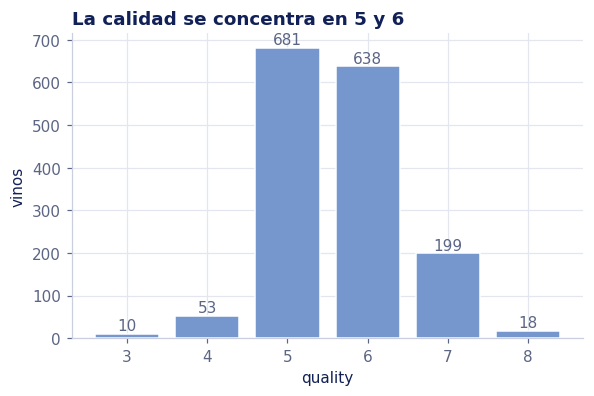

Vinos con quality ≥ 7: 217 (13.6%)


In [4]:
conteo = vinos["quality"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.bar(conteo.index, conteo.values, color=AZUL, edgecolor="white")
for k, v in conteo.items():
    ax.text(k, v + 8, str(v), ha="center", color=GRIS)
ax.set_xlabel("quality")
ax.set_ylabel("vinos")
ax.set_title("La calidad se concentra en 5 y 6")
plt.show()

print(f"Vinos con quality ≥ 7: {(vinos['quality'] >= 7).sum()} ({(vinos['quality'] >= 7).mean():.1%})")

**Lectura.** Más de 80 % de los vinos tiene calidad 5 o 6, y apenas 13.6 % llega a 7 o más. Es un desbalance importante para la parte de clasificación: un modelo que siempre diga «no bueno» ya acierta alrededor de 86 %.

### Distribución de las variables

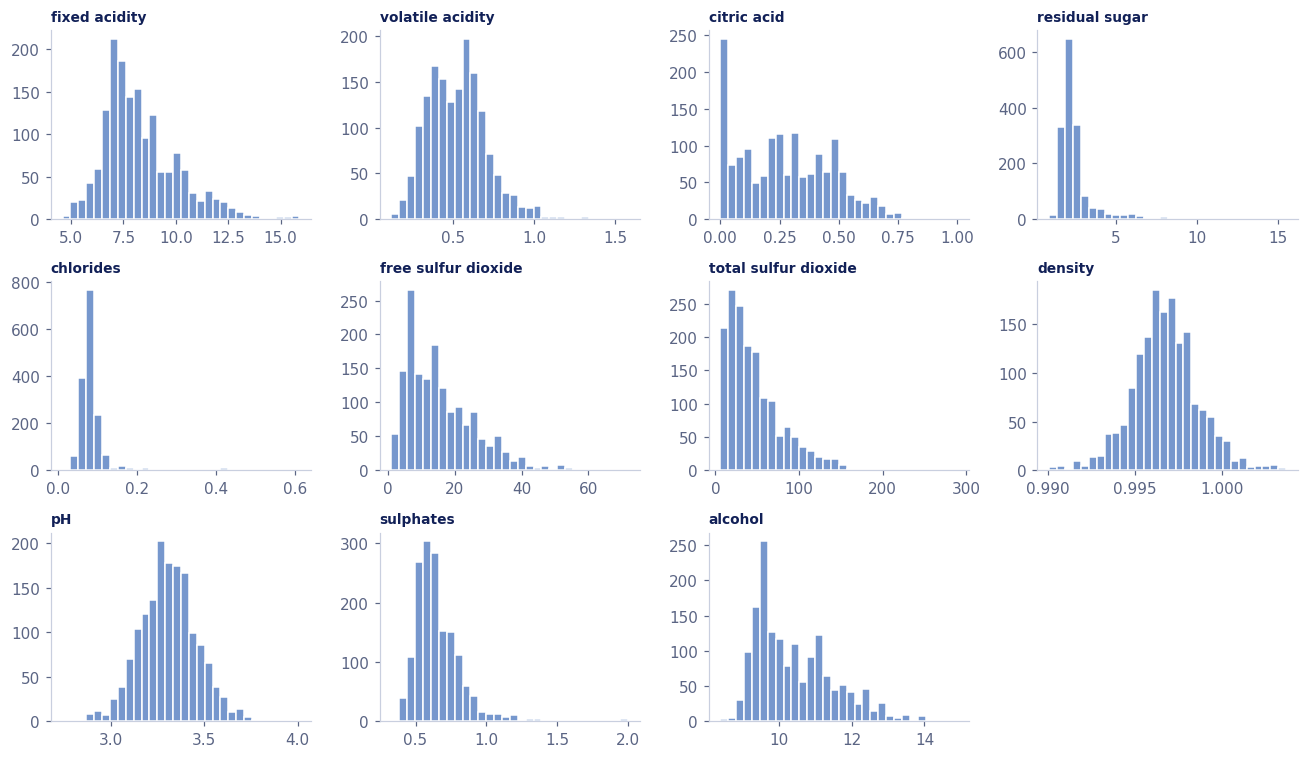

,asimetría
chlorides,5.68
residual sugar,4.54
sulphates,2.43
total sulfur dioxide,1.52
free sulfur dioxide,1.25
fixed acidity,0.98
alcohol,0.86
volatile acidity,0.67
citric acid,0.32
pH,0.19


In [5]:
vars_x = [c for c in vinos.columns if c != "quality"]

fig, axes = plt.subplots(3, 4, figsize=(12, 7))
for ax, c in zip(axes.ravel(), vars_x):
    ax.hist(vinos[c], bins=30, color=AZUL, edgecolor="white")
    ax.set_title(c, fontsize=9)
    ax.grid(False)
axes.ravel()[-1].axis("off")
fig.tight_layout()
plt.show()

vinos[vars_x].skew().round(2).sort_values(ascending=False).to_frame("asimetría")

**Lectura.** Varias variables tienen cola larga a la derecha, sobre todo chlorides (5.7), residual sugar (4.5) y sulphates (2.4). Pocos vinos con valores muy altos, no un error de captura evidente. La regresión lineal no exige que *x* sea normal (los supuestos son sobre los errores), así que no las transformamos.

### Valores atípicos

Valores fuera de 1.5·IQR por variable:
residual sugar          155
chlorides               112
sulphates                59
total sulfur dioxide     55
fixed acidity            49
density                  45
pH                       35
free sulfur dioxide      30
volatile acidity         19
alcohol                  13
citric acid               1

Vinos con algún valor fuera de 3·IQR: 164 de 1599


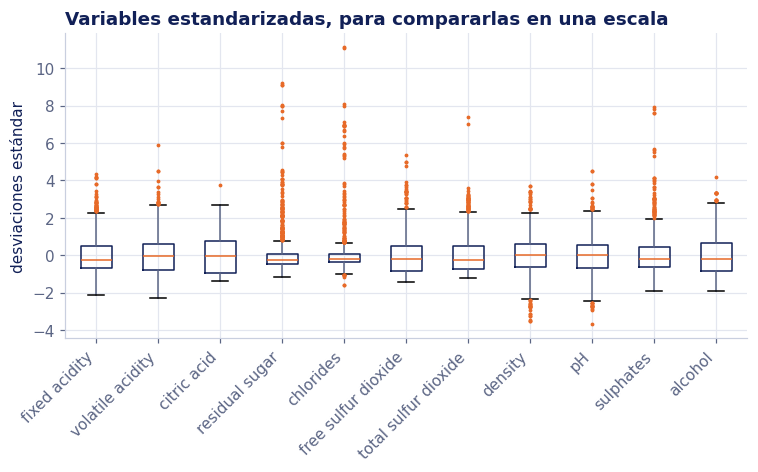

In [6]:
q1, q3 = vinos[vars_x].quantile(0.25), vinos[vars_x].quantile(0.75)
iqr = q3 - q1
fuera_15 = ((vinos[vars_x] < q1 - 1.5 * iqr) | (vinos[vars_x] > q3 + 1.5 * iqr)).sum()
extremos = ((vinos[vars_x] < q1 - 3 * iqr) | (vinos[vars_x] > q3 + 3 * iqr)).any(axis=1)

print("Valores fuera de 1.5·IQR por variable:")
print(fuera_15.sort_values(ascending=False).to_string())
print(f"\nVinos con algún valor fuera de 3·IQR: {extremos.sum()} de {len(vinos)}")

fig, ax = plt.subplots(figsize=(8, 3.6))
z = (vinos[vars_x] - vinos[vars_x].mean()) / vinos[vars_x].std()
ax.boxplot([z[c] for c in vars_x], tick_labels=vars_x, vert=True,
           flierprops=dict(marker=".", markerfacecolor=NARANJA, markeredgecolor=NARANJA, markersize=3),
           boxprops=dict(color=AZUL_OSCURO), medianprops=dict(color=NARANJA), whiskerprops=dict(color=GRIS))
ax.set_ylabel("desviaciones estándar")
ax.set_title("Variables estandarizadas, para compararlas en una escala")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.show()

**Lectura.** Hay muchos valores fuera de 1.5·IQR (por ejemplo, 155 en residual sugar y 112 en chlorides) y 164 vinos con algún valor extremo. Son mediciones fisicoquímicas de vinos reales y no hay un valor imposible (como un pH fuera de 0 a 14), así que no hay base para borrarlos. Los dejamos, sabiendo que la regresión por mínimos cuadrados es sensible a ellos.

### Relación con la calidad

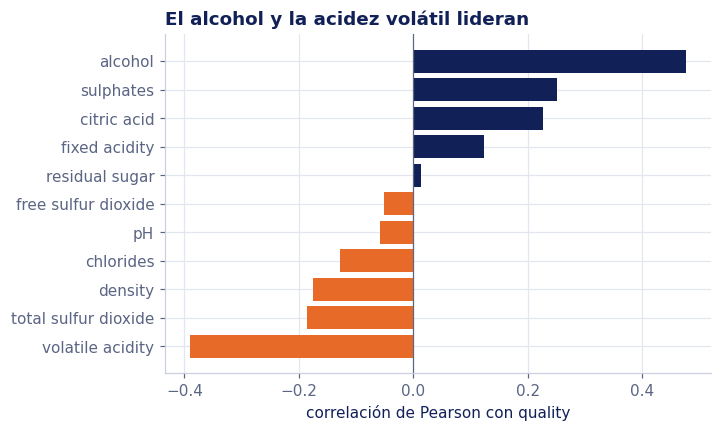

,volatile acidity,total sulfur dioxide,density,chlorides,pH,free sulfur dioxide,residual sugar,fixed acidity,citric acid,sulphates,alcohol
r con quality,-0.391,-0.185,-0.175,-0.129,-0.058,-0.051,0.014,0.124,0.226,0.251,0.476


In [7]:
corr = vinos.corr()["quality"].drop("quality").sort_values()

fig, ax = plt.subplots(figsize=(6.4, 4))
colores = [NARANJA if v < 0 else AZUL_OSCURO for v in corr.values]
ax.barh(corr.index, corr.values, color=colores)
ax.axvline(0, color=GRIS, linewidth=0.8)
ax.set_xlabel("correlación de Pearson con quality")
ax.set_title("El alcohol y la acidez volátil lideran")
plt.show()

corr.round(3).to_frame("r con quality").T

**Lectura.** El alcohol (0.48) es la variable con la asociación más fuerte con la calidad, seguida de la acidez volátil (−0.39, más acidez, peor vino) y los sulfatos (0.25). Ninguna correlación individual pasa de 0.5, así que no esperamos un R² alto: un modelo con las 11 variables captará algo más, pero la calidad sensorial tiene mucho ruido que estas mediciones no explican.

### Colinealidad entre predictoras

In [8]:
def vif(X):
    # VIF_j = 1 / (1 - R²_j), con R²_j de regresar la variable j contra las demás
    salida = {}
    for c in X.columns:
        otras = X.drop(columns=c)
        r2 = LinearRegression().fit(otras, X[c]).score(otras, X[c])
        salida[c] = 1 / (1 - r2)
    return pd.Series(salida).sort_values(ascending=False)

print(vif(vinos[vars_x]).round(1).to_string())
print("\nCorrelación entre fixed acidity y density:",
      round(vinos["fixed acidity"].corr(vinos["density"]), 2))
print("Correlación entre fixed acidity y citric acid:",
      round(vinos["fixed acidity"].corr(vinos["citric acid"]), 2))

fixed acidity           7.8
density                 6.3
pH                      3.3
citric acid             3.1
alcohol                 3.0
total sulfur dioxide    2.2
free sulfur dioxide     2.0
volatile acidity        1.8
residual sugar          1.7
chlorides               1.5
sulphates               1.4

Correlación entre fixed acidity y density: 0.67
Correlación entre fixed acidity y citric acid: 0.67


**Lectura.** Los factores de inflación de la varianza (VIF) más altos son los de fixed acidity (7.8) y density (6.3). Por convención, valores arriba de 5 a 10 son motivo de revisión y aquí ninguno llega a 10. Hay colinealidad moderada (la acidez fija se mueve junto con la densidad y el ácido cítrico), pero nada parecido al caso de s1 y s2 de la sesión anterior. Conservamos las 11 variables; solo conviene recordar que los coeficientes individuales deben leerse con cautela.

## 2. Limpieza

### Filas duplicadas

Este archivo es conocido por tener filas repetidas: vinos con las 12 columnas idénticas. Contamos cuántas hay.

In [9]:
n_dup = vinos.duplicated().sum()
print(f"Filas duplicadas (excluyendo la primera aparición): {n_dup} de {len(vinos)} ({n_dup/len(vinos):.1%})")
vinos[vinos.duplicated(keep=False)].sort_values(list(vinos.columns)).head(6)

Filas duplicadas (excluyendo la primera aparición): 240 de 1599 (15.0%)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
142,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.9916,3.68,0.79,14.0,6
144,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.9916,3.68,0.79,14.0,6
131,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.9937,3.63,0.63,13.0,5
132,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.9937,3.63,0.63,13.0,5
1488,5.6,0.54,0.04,1.7,0.049,5.0,13.0,0.9942,3.72,0.58,11.4,5
1491,5.6,0.54,0.04,1.7,0.049,5.0,13.0,0.9942,3.72,0.58,11.4,5


**Decisión.** Eliminamos las duplicadas y dejamos la primera aparición de cada una. Con 11 medidas continuas, que dos vinos distintos coincidan en todas es muy improbable, así que casi seguro son capturas repetidas de la misma muestra. Importa para la evaluación: al hacer la partición 80/20, una copia puede caer en entrenamiento y otra en prueba, y el modelo «predice» un vino que ya vio. Eso infla el desempeño en prueba. Más adelante comparamos los resultados con y sin este paso.

In [10]:
limpio = vinos.drop_duplicates().reset_index(drop=True)
print(f"Antes: {len(vinos)} vinos · Después: {len(limpio)} vinos")

comparacion = pd.DataFrame({
    "antes": vinos["quality"].value_counts(normalize=True).sort_index(),
    "después": limpio["quality"].value_counts(normalize=True).sort_index(),
}).round(3)
print(f"\nVinos con quality ≥ 7: antes {(vinos['quality'] >= 7).mean():.1%} · después {(limpio['quality'] >= 7).mean():.1%}")
comparacion

Antes: 1599 vinos · Después: 1359 vinos

Vinos con quality ≥ 7: antes 13.6% · después 13.5%


,antes,después
quality,,
3,0.006,0.007
4,0.033,0.039
5,0.426,0.425
6,0.399,0.394
7,0.124,0.123
8,0.011,0.013


**Lectura.** Quedan 1359 vinos. La distribución de quality casi no cambia y la proporción de vinos buenos sigue en 13.5 %, así que la limpieza no sesga el problema.

### No necesita corregir

- **Faltantes:** no hay, nada que imputar.
- **Ceros en citric acid:** hay 132 vinos con 0. Es un valor plausible (vinos sin ácido cítrico añadido), no un faltante codificado como cero. Se conservan.
- **Valores atípicos:** se conservan, por lo explicado arriba.
- **Escalas:** no se estandariza. LinearRegression resuelve los mínimos cuadrados de forma cerrada y las predicciones son las mismas con o sin estandarizar. Solo habría que hacerlo con descenso de gradiente.

## 3. Partición 80/20

In [11]:
X = limpio.drop(columns="quality")
y = limpio["quality"]

X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)
print(f"Entrenamiento: {len(X_ent)} vinos · Prueba: {len(X_pru)} vinos")

Entrenamiento: 1087 vinos · Prueba: 272 vinos


El modelo se ajusta con el 80 % de los vinos y se evalúa con el 20 % que no vio. Para la clasificación se usa la misma partición (mismos test_size y random_state sobre las mismas filas), de modo que cambia la variable objetivo pero no los vinos de prueba.

## 4. Regresión: predecir `quality`

In [12]:
modelo = LinearRegression().fit(X_ent, y_ent)
y_hat = modelo.predict(X_pru)

# Línea base: predecir siempre el promedio de entrenamiento
y_base = np.full(len(y_pru), y_ent.mean())

def rmse(y_real, y_pred):
    return np.sqrt(mean_squared_error(y_real, y_pred))

resultados = pd.DataFrame({
    "RMSE": [rmse(y_pru, y_hat), rmse(y_pru, y_base)],
    "R²": [r2_score(y_pru, y_hat), r2_score(y_pru, y_base)],
}, index=["regresión lineal", "siempre el promedio"])
resultados.round(3)

,RMSE,R²
regresión lineal,0.657,0.392
siempre el promedio,0.844,-0.006


**Lectura.** La regresión baja el RMSE de 0.84 a 0.66 puntos de calidad y alcanza un R² de 0.39, contra ≈ 0 de la línea base. Es una mejora real, pero modesta: el error típico sigue siendo de dos tercios de punto en una escala donde casi todos los vinos están entre 5 y 6. El R² de la línea base no es exactamente 0 porque el promedio de entrenamiento no coincide con el de prueba. Ese es el signo de que R² se calcula con el promedio de los datos que se evalúan.

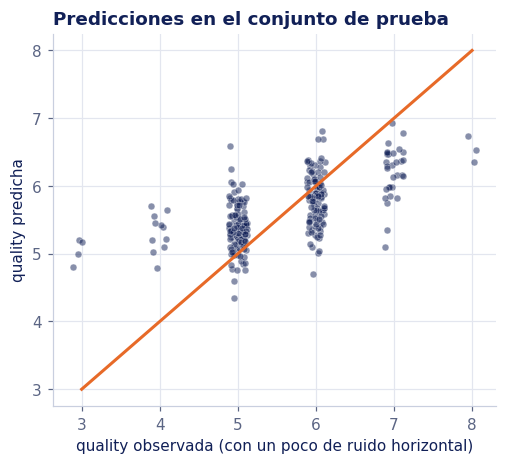

In [13]:
fig, ax = plt.subplots(figsize=(5.2, 4.4))
rng = np.random.default_rng(SEMILLA)
ax.scatter(y_pru + rng.uniform(-0.12, 0.12, len(y_pru)), y_hat, s=20, color=AZUL_OSCURO, alpha=0.5, edgecolor="white", linewidth=0.4)
ax.plot([3, 8], [3, 8], color=NARANJA, linewidth=2)
ax.set_xlabel("quality observada (con un poco de ruido horizontal)")
ax.set_ylabel("quality predicha")
ax.set_title("Predicciones en el conjunto de prueba")
plt.show()

**Lectura.** La línea naranja sería la predicción perfecta. Las predicciones se apretujan entre 5 y 7: el modelo casi no se atreve a predecir calidades extremas, y los vinos de 3, 4 y 8 quedan mal estimados. Es lo esperable con pocos ejemplos en las colas.

## 5. Clasificación con la misma regresión

Definimos bueno = 1 si quality ≥ 7 y 0 en caso contrario. Ajustamos **la misma** LinearRegression, pero ahora sobre esa columna de 0 y 1, y clasificamos como bueno si ŷ ≥ 0.5.

In [14]:
bueno = (limpio["quality"] >= 7).astype(int)
b_ent = bueno.loc[X_ent.index]
b_pru = bueno.loc[X_pru.index]

modelo_c = LinearRegression().fit(X_ent, b_ent)
p_hat = modelo_c.predict(X_pru)           # ŷ: un número real, no una probabilidad
clase = (p_hat >= 0.5).astype(int)

aciertos = (clase == b_pru).mean()
aciertos_base = (b_pru == 0).mean()       # predecir siempre «no bueno»
fuera = (p_hat < 0) | (p_hat > 1)

print(f"Vinos buenos en prueba:                {b_pru.sum()} de {len(b_pru)} ({b_pru.mean():.1%})")
print(f"Aciertos de la recta:                  {aciertos:.2%}")
print(f"Aciertos de predecir siempre «no bueno»: {aciertos_base:.2%}")
print(f"ŷ fuera de [0, 1]:                     {fuera.sum()} de {len(p_hat)} ({fuera.mean():.1%})")
print(f"   por debajo de 0: {(p_hat < 0).sum()} · por encima de 1: {(p_hat > 1).sum()}")
print(f"   rango de ŷ: de {p_hat.min():.3f} a {p_hat.max():.3f}")

Vinos buenos en prueba:                34 de 272 (12.5%)
Aciertos de la recta:                  88.24%
Aciertos de predecir siempre «no bueno»: 87.50%
ŷ fuera de [0, 1]:                     60 de 272 (22.1%)
   por debajo de 0: 60 · por encima de 1: 0
   rango de ŷ: de -0.189 a 0.604


**Lectura.** La recta acierta 88.2 %, apenas 0.7 puntos más que decir siempre «no bueno» (87.5 %). Con el desbalance, el porcentaje de aciertos casi no distingue un modelo útil de uno que no hace nada. Además, 60 de las 272 salidas (22 %) son negativas, es decir, no se pueden leer como probabilidad.

Veamos qué pasa con los vinos buenos, que son los que importan.

In [15]:
vp = ((clase == 1) & (b_pru == 1)).sum()
print(f"La recta marcó como buenos: {clase.sum()} vinos")
print(f"De esos, realmente buenos:  {vp}")
print(f"Vinos buenos detectados:    {vp} de {b_pru.sum()} ({vp / b_pru.sum():.0%})")

La recta marcó como buenos: 6 vinos
De esos, realmente buenos:  4
Vinos buenos detectados:    4 de 34 (12%)


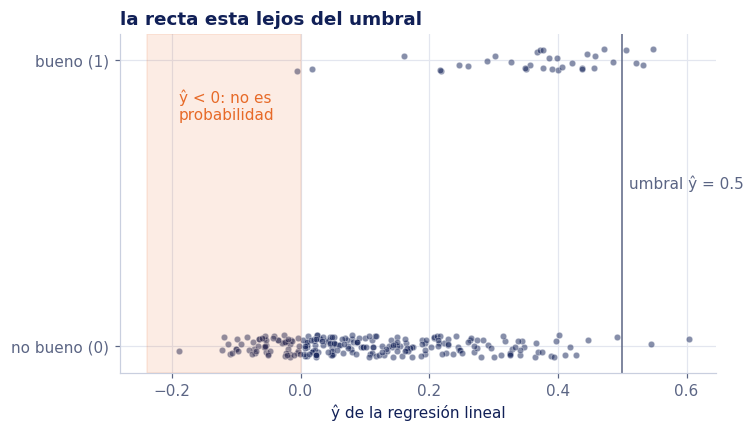

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
rng = np.random.default_rng(SEMILLA)
ax.scatter(p_hat, b_pru + rng.uniform(-0.04, 0.04, len(b_pru)), s=18, color=AZUL_OSCURO, alpha=0.5, edgecolor="white", linewidth=0.4)
ax.axvline(0.5, color=GRIS, linewidth=1)
ax.text(0.51, 0.55, "umbral ŷ = 0.5", color=GRIS)
ax.axvspan(p_hat.min() - 0.05, 0, color=NARANJA, alpha=0.12)
ax.text(p_hat.min(), 0.9, "ŷ < 0: no es\nprobabilidad", color=NARANJA, va="top")
ax.set_yticks([0, 1], ["no bueno (0)", "bueno (1)"])
ax.set_xlabel("ŷ de la regresión lineal")
ax.set_title("la recta esta lejos del umbral")
plt.show()

**Lectura.** Casi todos los puntos quedan a la izquierda del umbral, tanto los vinos buenos como los demás, y la zona sombreada muestra los valores negativos. Los vinos buenos no se separan bien: sus predicciones se traslapan con las de los no buenos.

### Sensibilidad

Repetimos los dos experimentos con los 1599 vinos originales, para ver cuánto pesa la decisión de limpieza.

In [17]:
def evaluar(datos):
    X_ = datos.drop(columns="quality"); y_ = datos["quality"]
    Xe, Xp, ye, yp = train_test_split(X_, y_, test_size=0.2, random_state=SEMILLA)
    ph = LinearRegression().fit(Xe, ye).predict(Xp)
    be, bp = (ye >= 7).astype(int), (yp >= 7).astype(int)
    q = LinearRegression().fit(Xe, be).predict(Xp)
    return {
        "RMSE": rmse(yp, ph),
        "R²": r2_score(yp, ph),
        "RMSE (promedio)": rmse(yp, np.full(len(yp), ye.mean())),
        "aciertos": ((q >= 0.5).astype(int) == bp).mean(),
        "aciertos (siempre no)": (bp == 0).mean(),
        "ŷ fuera de [0,1]": int(((q < 0) | (q > 1)).sum()),
        "n prueba": len(yp),
    }

pd.DataFrame({"con duplicados": evaluar(vinos), "sin duplicados": evaluar(limpio)}).round(3)

,con duplicados,sin duplicados
RMSE,0.625,0.657
R²,0.403,0.392
RMSE (promedio),0.811,0.844
aciertos,0.862,0.882
aciertos (siempre no),0.853,0.875
"ŷ fuera de [0,1]",82.000,60.000
n prueba,320.000,272.000


**Lectura.** Con duplicados el R² sale algo más alto (0.40 contra 0.39) y el RMSE parece mejor (0.62 contra 0.66), pero parte de esa ganancia viene de evaluar con vinos repetidos que el modelo ya vio. Las conclusiones cualitativas no cambian: la recta casi empata con la línea base como clasificador y una parte considerable de sus salidas queda fuera de [0, 1]. Reportamos los resultados **sin duplicados** por ser la evaluación más honesta.

## 6. Conclusión

 Para predecir quality, la recta redujo el RMSE de 0.84 a 0.66 y obtuvo un R² de 0.39 frente a ≈ 0 del promedio. Para clasificar, el 88.2 % de aciertos parece alto pero casi no supera el 87.5 % de decir siempre "no bueno", porque solo 12.5 % de los vinos de prueba son buenos; de hecho la recta marcó apenas 6 vinos como buenos y detectó 4 de los 34 que existen. Lo que le falla a la recta como clasificador es que minimiza un error cuadrático sobre valores 0 y 1 sin ninguna restricción: sus salidas no están acotadas a [0, 1] (60 de 272 quedaron por debajo de 0), así que no son probabilidades, y al ajustarse a una clase minoritaria el modelo casi nunca alcanza el umbral de 0.5. Hace falta un modelo cuya salida sea una probabilidad por construcción, como el de regresión logística.

## Declaración de uso de IA generativa

Se utilizó el asistente de inteligencia artificial Claude (Anthropic) en la elaboración de este notebook. La autora revisó el contenido y es responsable de su exactitud.

## Referencias

- Cortez, P., Cerdeira, A., Almeida, F., Matos, T. y Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems*, 47(4), 547-553.
- UCI Machine Learning Repository: *Wine Quality*.
- Pedregosa, F. *et al.* (2011). Scikit-learn: Machine learning in Python. *JMLR*, 12, 2825-2830.